In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
units = pd.read_csv('units_L234.csv').copy()
print(units.columns)

Index(['pt_root_id', 'pt_position_x', 'pt_position_y', 'pt_position_z',
       'classification_system', 'brain_area', 'strategy_dendrite',
       'strategy_axon', 'layer', 'gOSI_data', 'pvals_ori_fdr', 'selective_ori',
       'pvals_dir_fdr', 'pref_ori_fit'],
      dtype='object')


In [50]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

selected_mask (6448, 10)


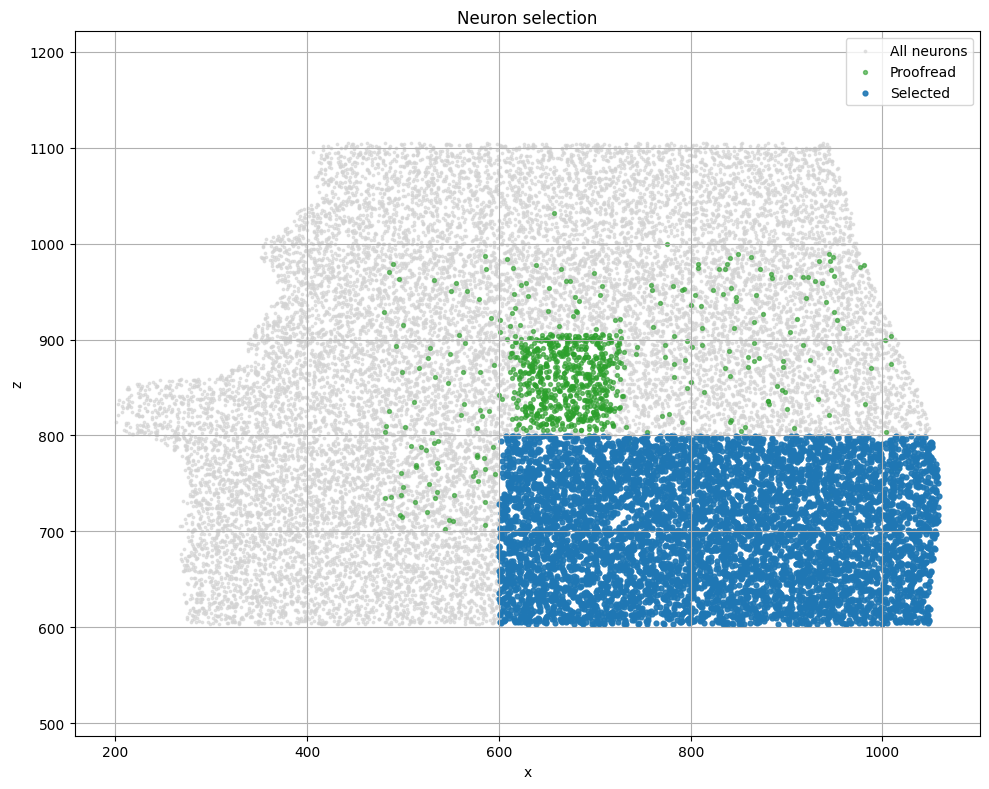

In [51]:
units_cleaned = clean_dataset(units)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

selected_mask = units_cleaned[(units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600)]

print("selected_mask", selected_mask.shape)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [52]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (selected_mask['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (selected_mask['layer'] == 'L4')

In [53]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
print(E_L23.shape)
I_L23 = selected_mask[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = selected_mask[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = selected_mask[mask_inh & mask_l4].copy().reset_index(drop=True)

print(E_L23)

(3408, 10)
              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691136084469356     862.910950     166.053955     674.440002   
1     864691135156852068     895.572205     134.926117     688.919983   
2     864691135772608763     930.297302     153.639816     719.039978   
3     864691135489181498     929.746094     247.324280     750.239990   
4     864691135856593454     669.007080     172.089081     619.799988   
...                  ...            ...            ...            ...   
3403  864691135644599279     888.780762      86.983772     613.840027   
3404  864691135468547212     650.351379     123.172989     799.400024   
3405  864691136362442466     788.676208     101.803474     795.919983   
3406  864691135429292592    1028.933472     105.669991     641.440002   
3407  864691136238038799     708.155273     187.977524     799.599976   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          n

In [54]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [55]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [56]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [57]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [58]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [59]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    id_to_pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]

    positions = id_to_pos.loc[
        np.array(all_ids)
    ].values.astype(np.float32)

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values

    positions = (positions - positions.mean(axis=0, keepdims=True)) / (positions.std(axis=0, keepdims=True)+ 1e-8)

    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = [
    "pre_pt_position_x",
    "pre_pt_position_y",
    "pre_pt_position_z",
    "post_pt_position_x",
    "post_pt_position_y",
    "post_pt_position_z",
    ]

    print(df)

    X = df[features].to_numpy(dtype=np.float32)
    y = df['label'].values

    return X, y, features, pre_idx, post_idx, positions

In [60]:
path, pre, post = pathways[0]
print(pre)
X, y, features, pre_idx, post_idx, positions = build_dataset(pre, post, synapses, metric=['Euclidean'])

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691136084469356     862.910950     166.053955     674.440002   
1     864691135156852068     895.572205     134.926117     688.919983   
2     864691135772608763     930.297302     153.639816     719.039978   
3     864691135489181498     929.746094     247.324280     750.239990   
4     864691135856593454     669.007080     172.089081     619.799988   
...                  ...            ...            ...            ...   
3403  864691135644599279     888.780762      86.983772     613.840027   
3404  864691135468547212     650.351379     123.172989     799.400024   
3405  864691136362442466     788.676208     101.803474     795.919983   
3406  864691135429292592    1028.933472     105.669991     641.440002   
3407  864691136238038799     708.155273     187.977524     799.599976   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          none  L2/3  

In [61]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_hybrid_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 30
PATIENCE = 5
LR = 1e-3
DIMS = [1,2,3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [62]:
# =========================
# Hybrid model: geometry + latent embedding
# =========================

class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        dim=2,
        hidden=64,
        positions=None,
    ):
        super().__init__()

        self.dim = dim

        # Latent part learned by backpropagation
        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # Fixed anatomical positions
        if positions is None:
            raise ValueError(
                "positions must be provided with shape (n_neurons, 3)"
            )

        positions = torch.as_tensor(
            positions,
            dtype=torch.float32
        )

        if positions.shape != (n_neurons, 3):
            raise ValueError(
                f"positions must have shape ({n_neurons}, 3), "
                f"got {positions.shape}"
            )

        self.register_buffer(
            "positions",
            positions
        )

        # For each neuron:
        # [x, y, z] + latent dim
        neuron_feature_dim = 3 + dim

        # For each pair:
        # pre features + post features
        input_dim = 2 * neuron_feature_dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        # Learned latent vectors
        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        # Fixed anatomical positions
        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # Hybrid neuron vectors
        h_pre = torch.cat(
            [pos_pre, z_pre],
            dim=1
        )

        h_post = torch.cat(
            [pos_post, z_post],
            dim=1
        )

        # Pair vector
        x = torch.cat(
            [h_pre, h_post],
            dim=1
        )

        logits = self.mlp(x).squeeze(1)

        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx)
        )

In [63]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx, positions = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

71408
11611056
              pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0         864691134884804602  864691136267238900  1.048946         793.389404   
1         864691134885076730  864691135719709489  0.017885         890.064514   
2         864691134885076730  864691135841733859  0.071092         890.064514   
3         864691134885518074  864691136700131694  0.041582         699.402466   
4         864691134885576442  864691136811834227  1.107519         927.851685   
...                      ...                 ...       ...                ...   
11682459  864691136238038799  864691136663328222  0.000000         708.155273   
11682460  864691136238038799  864691135644599279  0.000000         708.155273   
11682461  864691136238038799  864691135468547212  0.000000         708.155273   
11682462  864691136238038799  864691136362442466  0.000000         708.155273   
11682463  864691136238038799  864691135429292592  0.000000         708.155273   

          pr

In [64]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [65]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [66]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [41]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [42]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim, positions=positions).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
dim=01 | epoch=000 | train_loss=0.1759 | val_loss=0.0404 | val_auc=0.6717
dim=01 | epoch=001 | train_loss=0.0364 | val_loss=0.0351 | val_auc=0.7654
dim=01 | epoch=002 | train_loss=0.0341 | val_loss=0.0337 | val_auc=0.8261
dim=01 | epoch=003 | train_loss=0.0327 | val_loss=0.0323 | val_auc=0.8628
dim=01 | epoch=004 | train_loss=0.0314 | val_loss=0.0311 | val_auc=0.8832
dim=01 | epoch=005 | train_loss=0.0303 | val_loss=0.0301 | val_auc=0.8948
dim=01 | epoch=006 | train_loss=0.0294 | val_loss=0.0294 | val_auc=0.9016
dim=01 | epoch=007 | train_loss=0.0289 | val_loss=0.0290 | val_auc=0.9056
dim=01 | epoch=008 | train_loss=0.0285 | val_loss=0.0287 | val_auc=0.9080
dim=01 | epoch=009 | train_loss=0.0283 | val_loss=0.0286 | val_auc=0.9092
dim=01 | epoch=010 | train_loss=0.0282 | val_loss=0.0285 | val_auc=0.9099
dim=01 | epoch=011 | train_loss=0.0282 | val_loss=0.0285 | val_auc=0.9102
dim=01 | epoch=012 | train_loss=0.0281 | val_loss=0.0285 | val_auc=0.9105
dim=01 | epoch=013 |

KeyboardInterrupt: 

In [ ]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS
print(h5)
coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg.columns)

print(h5)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



<HDF5 file "microns.h5" (mode r)>
Index(['id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_supervoxel_id',
       'pt_root_id', 'id', 'created', 'valid', 'target_id', 'session',
       'scan_idx', 'unit_id', 'field', 'residual', 'score', 'pt_position',
       'bb_start_position', 'bb_end_position'],
      dtype='object')
<HDF5 file "microns.h5" (mode r)>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>


UnboundLocalError: cannot access local variable 'weights' where it is not associated with a value

In [95]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 3

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

# ============================================================
# Remove duplicates
# ============================================================

units_unique = (
    units_cleaned
    .drop_duplicates(
        subset="pt_root_id",
        keep="first"
    )
    .copy()
)

print(
    "Duplicates in units_unique:",
    units_unique["pt_root_id"].duplicated().sum()
)


# ============================================================
# Build df_Z_full
# ============================================================

df_Z_full = df_Z.merge(
    units_unique,
    on="pt_root_id",
    how="left"
)
print(df_Z_full.head())

Loaded model for dim=3
Best epoch: 29
Best val loss: 0.0278
Z shape: (3408, 3)
Duplicates in units_unique: 0
         z1        z2        z3  neuron_idx          pt_root_id  \
0  0.295527  0.061765 -0.035903           0  864691134884804602   
1  0.393337  0.458528 -0.195525           1  864691134885076730   
2  0.184997  0.404170 -0.113547           2  864691134885518074   
3 -0.039585  0.209743 -0.206995           3  864691134885576442   
4  0.376547 -0.451833 -0.209314           4  864691134885584634   

   pt_position_x  pt_position_y  pt_position_z classification_system  \
0     793.389404     242.525742     721.359985     excitatory_neuron   
1     890.064514     212.565536     651.479980     excitatory_neuron   
2     699.402466     200.638855     603.599976     excitatory_neuron   
3     927.851685     102.287254     669.320007     excitatory_neuron   
4     754.282288     122.629097     638.640015     excitatory_neuron   

  strategy_axon layer  gOSI_data selective_ori  pref_or

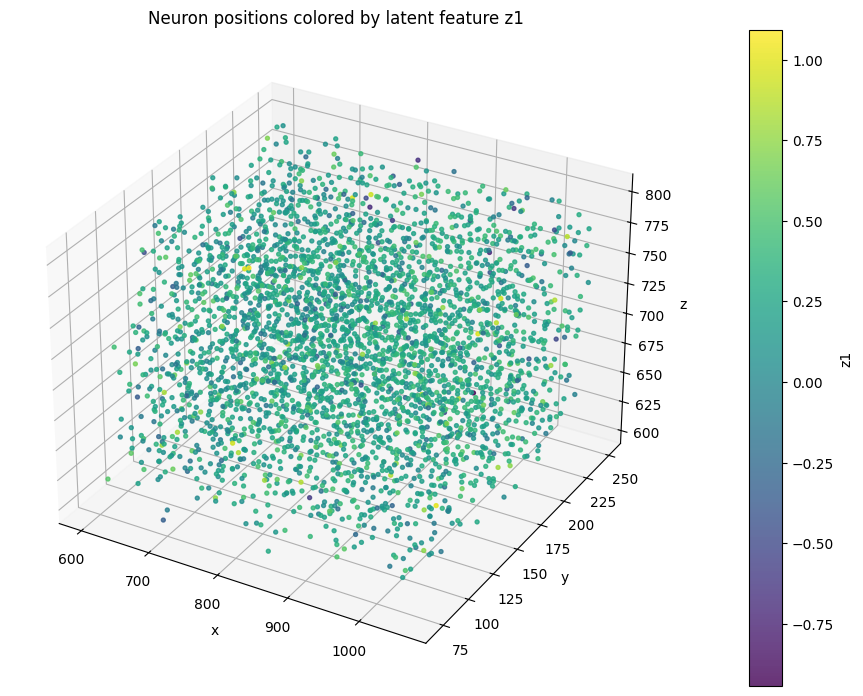

In [96]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


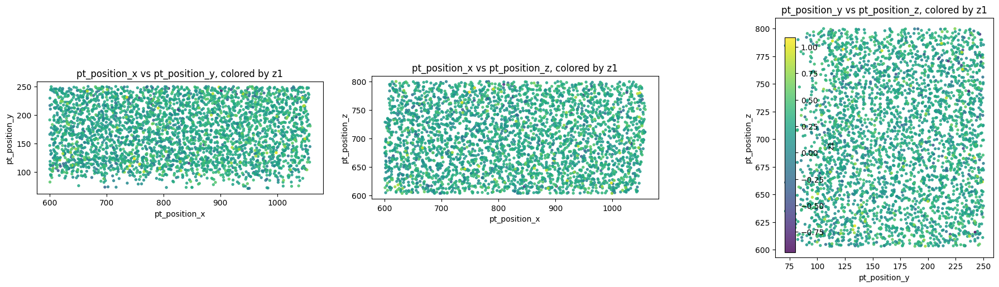

In [97]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Empirical P(connection) as a function of Z_pre and Z_post
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


N_BINS = 20
MIN_PAIRS_PER_CELL = 100


# Existing tensors -> NumPy
pre_np = pre_idx.detach().cpu().numpy()
post_np = post_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()


heatmaps = []
edges_by_dim = []


# ============================================================
# Compute empirical probabilities
# ============================================================

for k in range(DIM_TO_ANALYZE):

    z_pre = Z[pre_np, k]
    z_post = Z[post_np, k]

    z_edges = np.linspace(
        min(z_pre.min(), z_post.min()),
        max(z_pre.max(), z_post.max()),
        N_BINS + 1,
    )

    # Number of possible connections in each cell
    n_possible, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
    )

    # Number of observed connections in each cell
    n_connections, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
        weights=y_np,
    )

    # P(connection) = observed / possible
    empirical_probability = np.divide(
        n_connections,
        n_possible,
        out=np.full_like(
            n_connections,
            np.nan,
            dtype=float,
        ),
        where=n_possible > 0,
    )

    empirical_probability[
        n_possible < MIN_PAIRS_PER_CELL
    ] = np.nan

    heatmaps.append(empirical_probability)
    edges_by_dim.append(z_edges)


# Common color scale
vmax = np.nanmax([
    np.nanmax(heatmap)
    for heatmap in heatmaps
])


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    DIM_TO_ANALYZE,
    figsize=(5 * DIM_TO_ANALYZE, 4.5),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")


for k, ax in enumerate(axes):

    z_edges = edges_by_dim[k]

    im = ax.pcolormesh(
        z_edges,
        z_edges,
        heatmaps[k].T,
        shading="auto",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(
        rf"Latent dimension $Z_{k+1}$"
    )

    ax.set_xlabel(
        rf"Presynaptic value $Z_{{i,{k+1}}}$"
    )

    ax.set_ylabel(
        rf"Postsynaptic value $Z_{{j,{k+1}}}$"
    )


colorbar = fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.85,
)

colorbar.set_label(
    "Empirical connection probability"
)

colorbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

fig.suptitle(
    "Empirical connection probability in latent space",
    fontsize=14,
)

plt.savefig(
    "empirical_connection_probability_latent_heatmaps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


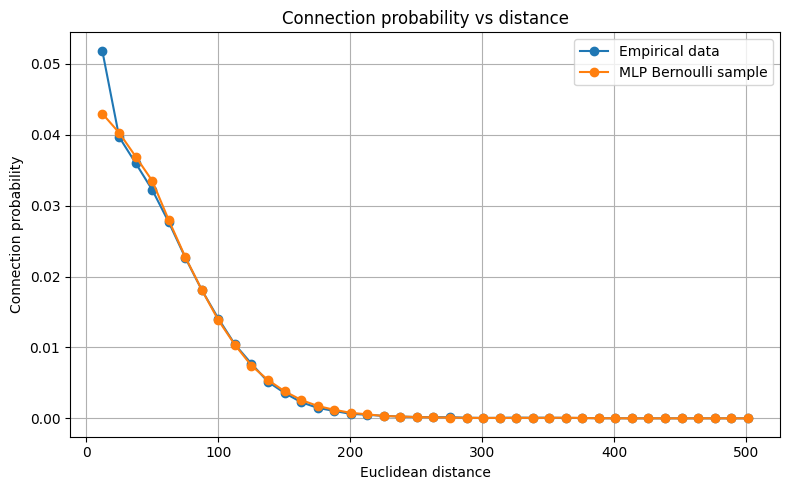

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 29
Best val loss: 0.0284


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.031

Analyzing dim = 2
Loaded best epoch: 29
Best val loss: 0.0281


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


...

corr(geometrical distance, latent distance) = 0.058

Analyzing dim = 5
Loaded best epoch: 29
Best val loss: 0.0275


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.025

Analyzing dim = 6
Loaded best epoch: 29
Best val loss: 0.0276


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.032


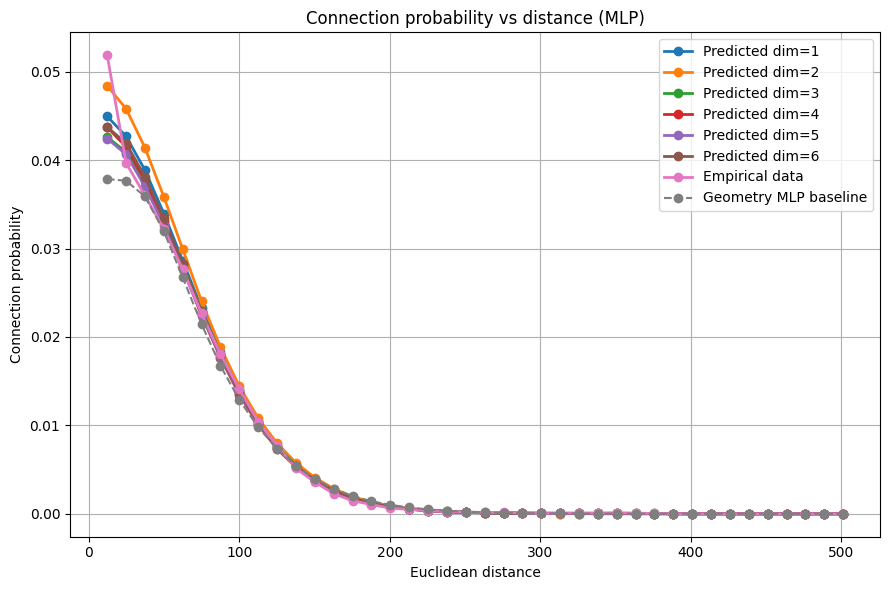

dim=6 corr=0.032


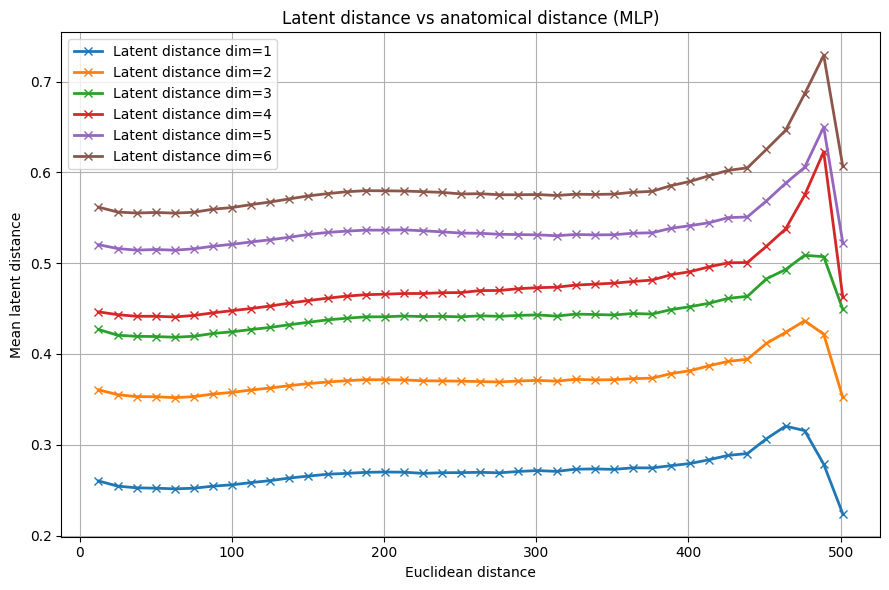

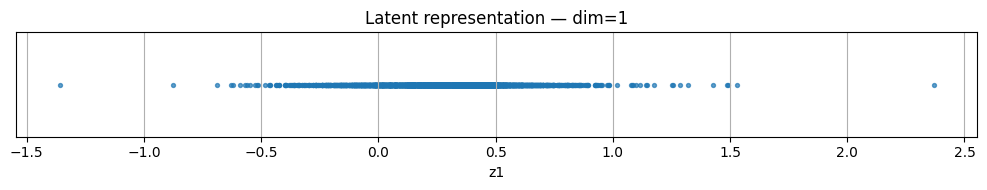

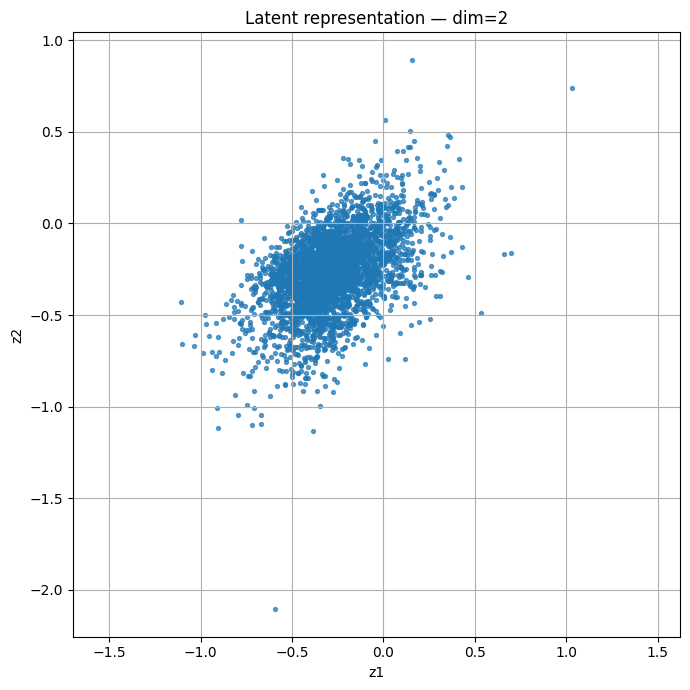

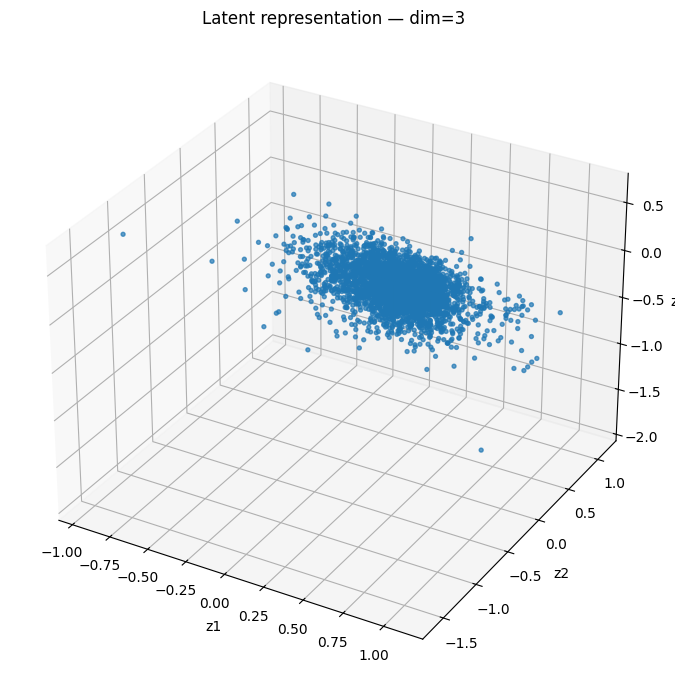

In [99]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3, 4, 5, 6]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)


plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [100]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np


# ============================================================
# Data
# ============================================================

df_Z_full = df_Z_full.merge(readout_unique[ 
    [ "pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(df_Z_full)


df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

R = np.stack(df_Z_readout["readout_weight"].values)

print("R shape:", R.shape)

threshold = 0.30

results = []

# ============================================================
# Correlations
# ============================================================

for z in latent_cols:

    z_values = df_Z_readout[z].values

    for j in range(512):

        rho, pval = spearmanr(
            z_values,
            R[:, j]
        )

        if np.abs(rho) >= threshold:

            results.append({
                "latent": z,
                "readout_dim": j,
                "rho": rho,
                "abs_rho": abs(rho),
                "pvalue": pval,
            })

corr_df = pd.DataFrame(results)

"""corr_df = corr_df.sort_values(
    "abs_rho",
    ascending=False
)"""

print(corr_df)

            z1        z2        z3  neuron_idx          pt_root_id  \
0     0.295527  0.061765 -0.035903           0  864691134884804602   
1     0.393337  0.458528 -0.195525           1  864691134885076730   
2     0.184997  0.404170 -0.113547           2  864691134885518074   
3    -0.039585  0.209743 -0.206995           3  864691134885576442   
4     0.376547 -0.451833 -0.209314           4  864691134885584634   
...        ...       ...       ...         ...                 ...   
3403  0.569942  0.771680 -0.927212        3403  864691135657776514   
3404  0.688454  0.820053 -0.647609        3404  864691136444759171   
3405  0.270877  1.120409 -0.417576        3405  864691136091466676   
3406  0.730678  0.651179 -0.622356        3406  864691136389610256   
3407  0.535895  0.782552 -0.305568        3407  864691135583278189   

      pt_position_x  pt_position_y  pt_position_z classification_system  \
0        793.389404     242.525742     721.359985     excitatory_neuron   
1        

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
    "readout_mu_x",
    "readout_mu_y"
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1', 'z2', 'z3']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit', 'readout_mu_x', 'readout_mu_y']


In [102]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.108474       0.021456       0.010894      0.027590      0.068037   
z2      -0.106083      -0.063280      -0.004138      0.030996     -0.100068   
z3      -0.045854      -0.027861       0.016092     -0.003256     -0.067124   

    readout_mu_y  
z1      0.035670  
z2     -0.057542  
z3     -0.008083  

=== Pearson correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.086922       0.002940      -0.006752      0.039893      0.057142   
z2      -0.100133      -0.075003      -0.018654      0.048431     -0.077376   
z3      -0.034511      -0.030399       0.018985      0.004144     -0.049021   

    readout_mu_y  
z1      0.024513  
z2     -0.047800  
z3      0.005786  


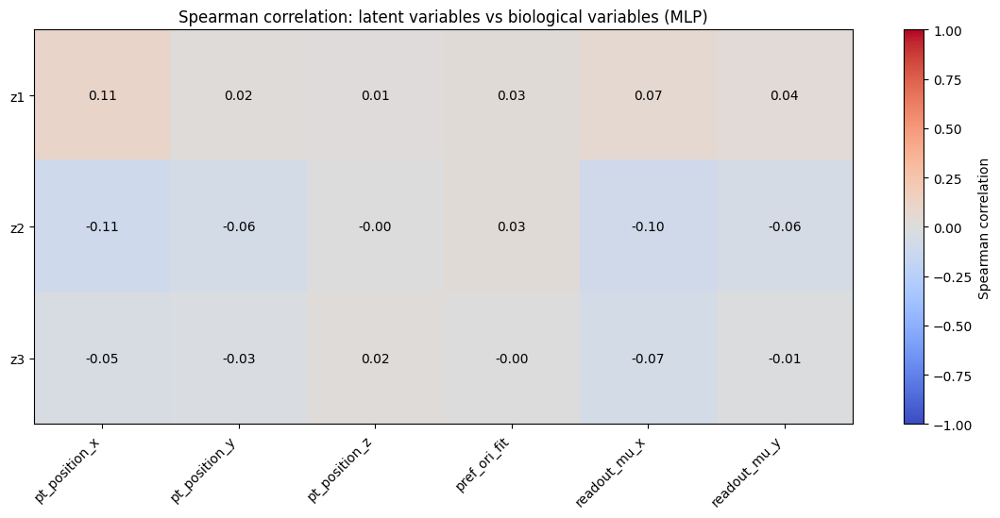

In [103]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z1  pt_position_x    0.108474
z2  pt_position_x    0.106083
    readout_mu_x     0.100068
z1  readout_mu_x     0.068037
z3  readout_mu_x     0.067124
z2  pt_position_y    0.063280
dtype: float64


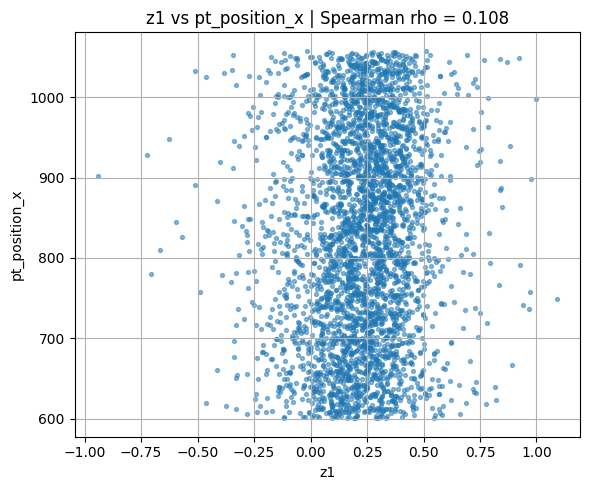

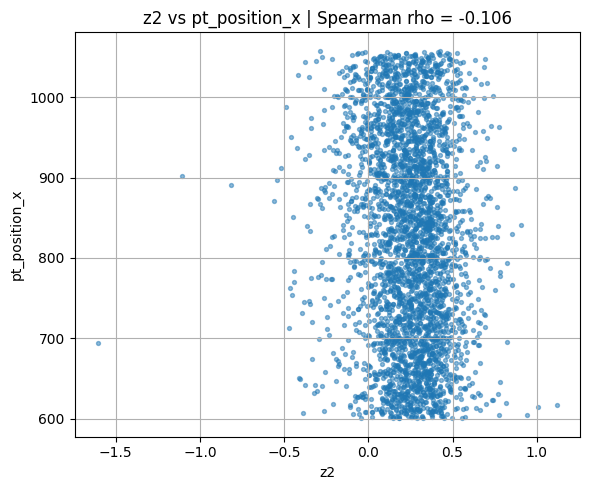

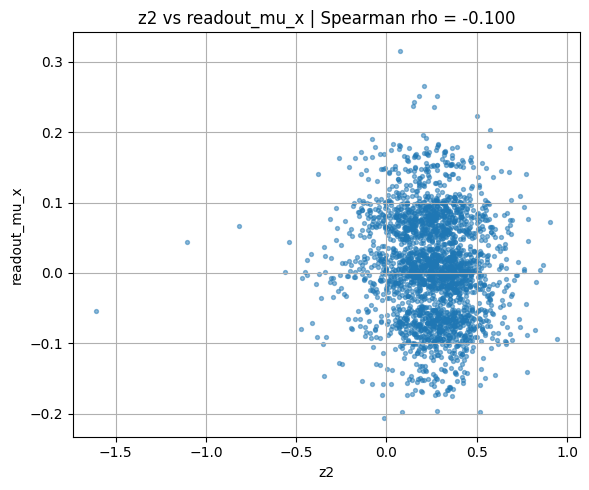

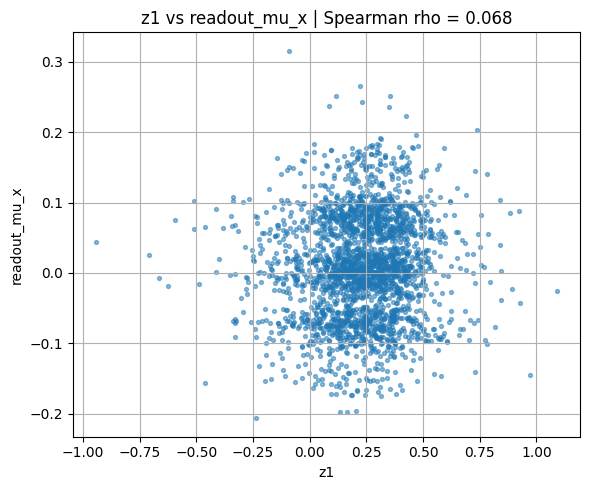

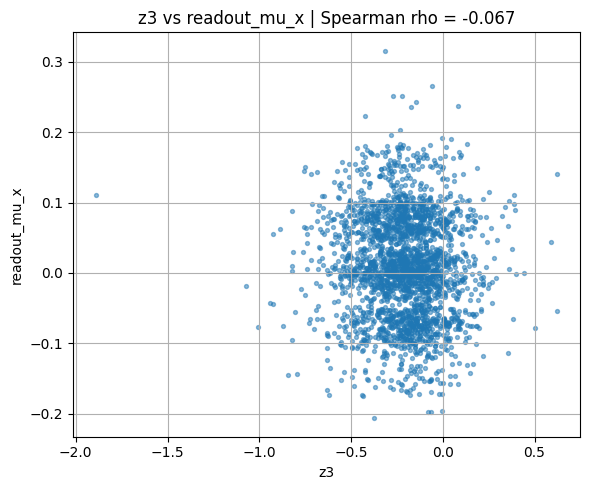

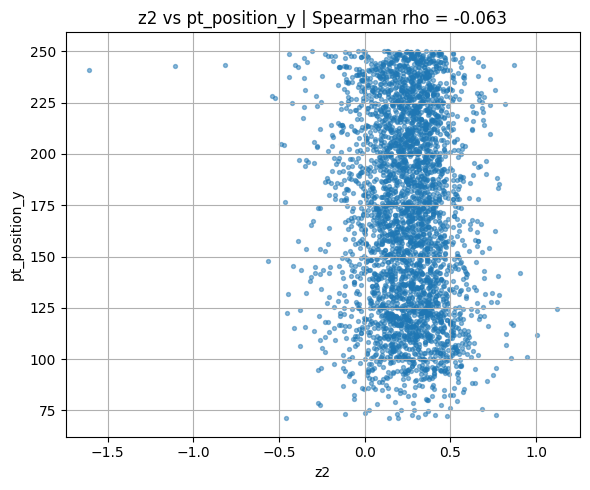

In [104]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

PCA explained variance: [0.6084067  0.20181923]


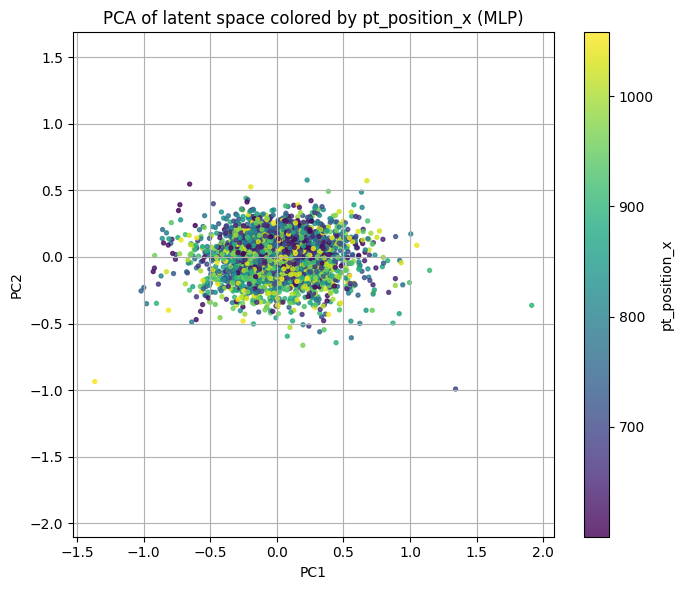

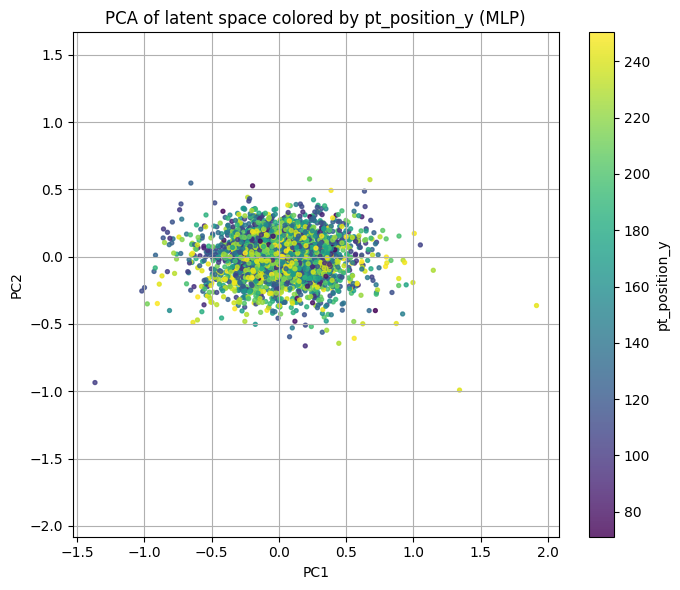

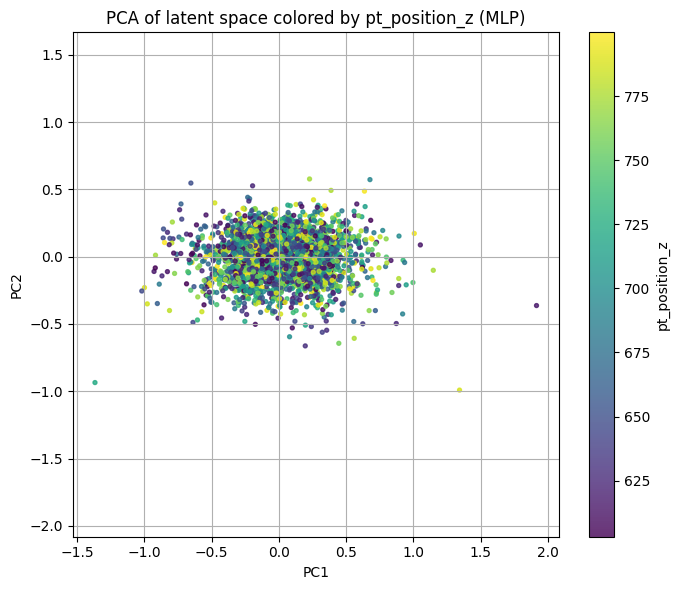

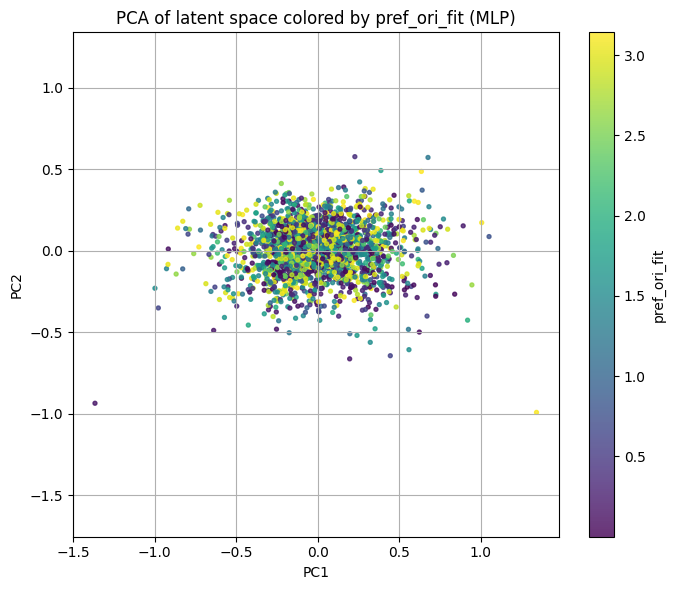

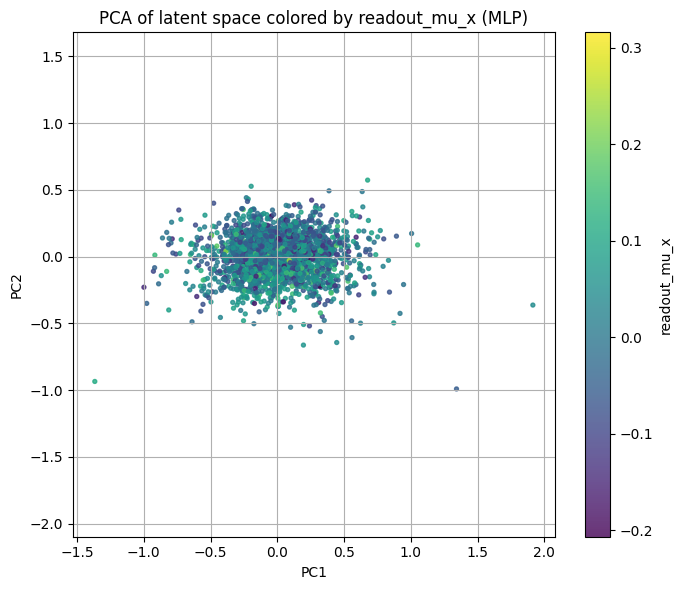

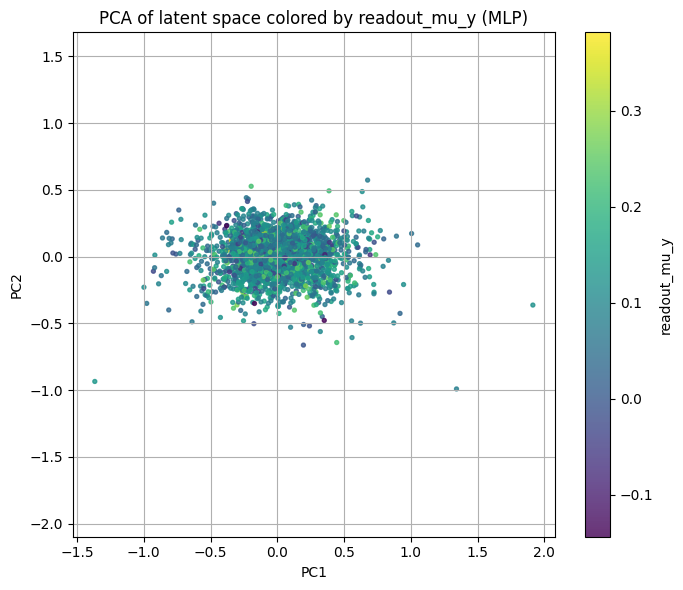

In [105]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

In [106]:
import pickle
import h5py
import pandas as pd

with open("MICrONS\\readout_info\\foundation_model.pkl", "rb") as f:
    foundation = pickle.load(f)

with open("MICrONS\\readout_info\\hierarchical_model.pkl", "rb") as f:
    hierarchical = pickle.load(f)

h5 = h5py.File("MICrONS\\microns.h5", "r")
print(h5.keys())

<KeysViewHDF5 ['brain_areas', 'sessions', 'types', 'videos']>


In [107]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

Z_valid shape: (2481, 6)
F shape: (2481, 512)
Spearman rho = -0.042, p = 1.60e-79


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_49856\1679691331.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = res.groupby("bin").agg(


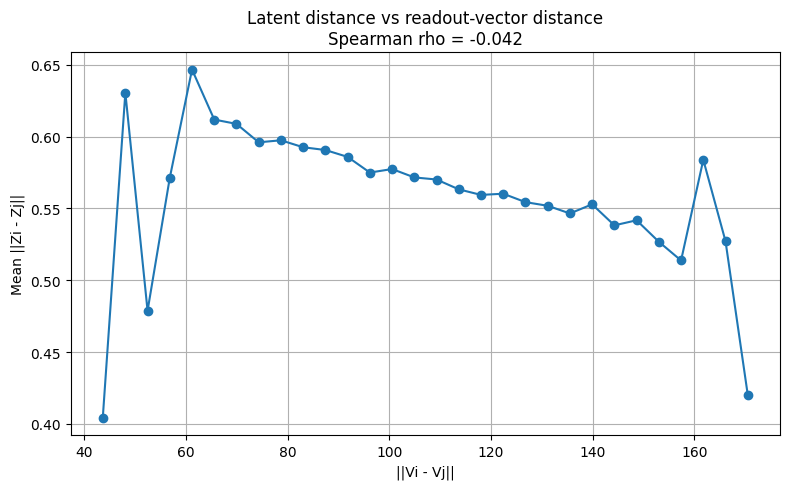

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

feature = "readout_weight"

# neurones valides
df = df_Z_full.dropna(subset=[feature]).copy()

idx = df["neuron_idx"].values

Z_valid = Z[idx]

# IMPORTANT : convertir la colonne de vecteurs en matrice
F = np.stack(
    df[feature].values
).astype(np.float32)

print("Z_valid shape:", Z_valid.shape)
print("F shape:", F.shape)

# -------------------------
# échantillonnage
# -------------------------

n_pairs = 200000
rng = np.random.default_rng(42)

i = rng.integers(0, len(df), n_pairs)
j = rng.integers(0, len(df), n_pairs)

mask = i != j
i = i[mask]
j = j[mask]

# -------------------------
# distances
# -------------------------

latent_dist = np.linalg.norm(
    Z_valid[i] - Z_valid[j],
    axis=1
)

feature_dist = np.linalg.norm(
    F[i] - F[j],
    axis=1
)

rho, pval = spearmanr(
    feature_dist,
    latent_dist
)

print(f"Spearman rho = {rho:.3f}, p = {pval:.2e}")

# -------------------------
# dataframe
# -------------------------

res = pd.DataFrame({
    "feature_dist": feature_dist,
    "latent_dist": latent_dist
})

res["bin"] = pd.cut(
    res["feature_dist"],
    bins=30
)

curve = res.groupby("bin").agg(
    mean_latent=("latent_dist", "mean"),
    n_pairs=("latent_dist", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# -------------------------
# plot
# -------------------------

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["mean_latent"],
    marker="o"
)

plt.xlabel("||Vi - Vj||")
plt.ylabel("Mean ||Zi - Zj||")
plt.title(
    f"Latent distance vs readout-vector distance\nSpearman rho = {rho:.3f}"
)

plt.grid(True)
plt.tight_layout()
plt.show()